# Running live

Diagrams in real time: background runs, parameter changes while running,
live plots, and samples from other threads such as a receiver.

In [1]:
import threading
import time

import numpy as np
import scipy.signal as sig

import sigline as sl

fs = 48_000.0

## 1. A background run paced to real time

`d.start()` returns at once; the run keeps real time: chunk $k$ is done no
earlier than $k \cdot$ `chunk` / `fs` after the start. `d.overruns` counts
chunks that finished late.

In [2]:
tone, noise, add = sl.Sine(1e3), sl.Noise(0.2, seed=1), sl.Sum()
lp, rx = sl.FIR(sig.firwin(101, 3e3, fs=fs)), sl.Scope("rx", keep=4800)
tone >> add["x0"]
noise >> add["x1"]
add >> lp >> rx
d = sl.Diagram(rx, fs=fs)

t0 = time.perf_counter()
d.start(0.5, chunk=1024)
print("running:", d.running)
d.wait()
print(f"0.5 s of signal took {time.perf_counter() - t0:.3f} s, overruns: {d.overruns}")

running: True


0.5 s of signal took 0.502 s, overruns: 0


`realtime=False` runs as fast as possible:

In [3]:
d.reset()
t0 = time.perf_counter()
d.start(5.0, chunk=4096, realtime=False).wait()
print(f"5 s of signal took {time.perf_counter() - t0:.3f} s")

5 s of signal took 0.054 s


## 2. Live plot and a change while running

`sl.watch(d, draw)` redraws while `d` runs; `draw(fig)` is any matplotlib
code. A timer retunes the tone after 0.5 s with `d.set`, which applies the
change between chunks.

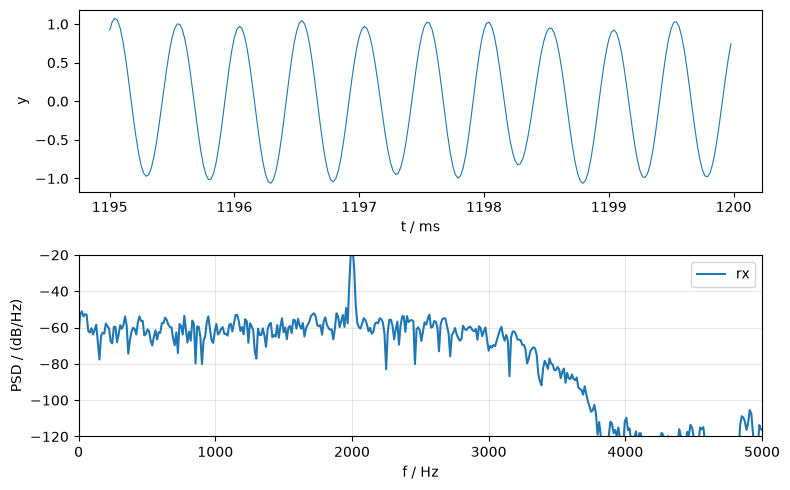

tone now at 2000.0 Hz


In [4]:
def draw(fig):
    ax1, ax2 = fig.subplots(2, 1)
    t, y = rx.snapshot()
    ax1.plot(1e3 * t[-240:], y[-240:], lw=0.8)  # last 5 ms
    ax1.set(xlabel="t / ms", ylabel="y")
    rx.psd(ax=ax2)
    ax2.set_xlim(0, 5e3)
    ax2.set_ylim(-120, -20)
    fig.tight_layout()


d.reset()
d.start(1.2, chunk=1024)
threading.Timer(0.5, d.set, args=(tone,), kwargs={"f": 2e3}).start()
fig = sl.watch(d, draw, interval=0.25, figsize=(8, 5))
print("tone now at", tone.f, "Hz")

## 3. Samples from another thread

A simulated receiver pushes 4096-sample blocks of complex IQ at its own pace
into a `FromQueue`; the diagram waits for them, so the receiver sets the
pace. A consumer thread reads the result from a `ToQueue`. This is how
device callbacks plug into a diagram.

In [5]:
fs_iq = 250_000.0
src, mix, sink = sl.FromQueue(), sl.Mixer(-25e3, "exp"), sl.ToQueue()
src >> mix >> sink
d_iq = sl.Diagram(sink, fs=fs_iq)

n_blocks, block = 30, 4096
x = np.exp(
    2j * np.pi * 25e3 * np.arange(n_blocks * block) / fs_iq
)  # carrier at +25 kHz


def receiver():
    for k in range(n_blocks):
        src.push(x[k * block : (k + 1) * block])
        time.sleep(block / fs_iq)  # real-time delivery


th = threading.Thread(target=receiver)
t0 = time.perf_counter()
th.start()
d_iq.start(n=n_blocks * block, chunk=2048)  # realtime off: FromQueue paces it
d_iq.wait()
th.join()
y = sink.pull(n_blocks * block)
took = time.perf_counter() - t0
print(f"{len(y)} samples in {took:.2f} s, underruns {src.underruns}")
print("mixed down to DC: max |y - 1| =", np.max(np.abs(y - 1)))

122880 samples in 0.50 s, underruns 0
mixed down to DC: max |y - 1| = 2.886564200273074e-11


## 4. Hardware

Same pattern with real devices (needs `sigline[rtlsdr]` and `sigline[audio]`
and the hardware, so not run here):

```python
sdr = sl.RtlSdrSource(145.8e6, gain=30)  # complex IQ
fm = sl.Func(lambda z: np.angle(z[1:] * np.conj(z[:-1])))  # naive, see note
d = sl.Diagram(..., fs=240_000)
d.start()                            # the receiver paces the run
d.set(sdr, center_freq=145.825e6)    # retune while running
sl.watch(d, draw)
d.stop()
```

The FM line above is only a sketch: a real demodulator keeps the last sample
between chunks, as every block must.

## Summary

- `d.start()` / `d.stop()` / `d.wait()`: background runs, paced to real time
  or by an external clock; `d.overruns` counts late chunks.
- `d.set` / `d.call`: changes between chunks.
- `sl.watch(d, draw)`: live plots from any matplotlib code.
- `FromQueue` / `ToQueue`: samples from and to other threads;
  `RtlSdrSource`, `AudioIn`, `AudioOut` build on them.